# Fashion MNIST — Neural Network Practical Tasks
**Tools:** Python, TensorFlow/Keras, Matplotlib

In this notebook I run small experiments on a simple neural network and try to **explain** what changes its performance.
I change **one setting at a time**, use the **same train/validation split** everywhere, and use the test set only at the end.

## Setup: load data, normalize, split

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [3]:
# normalize pixels to 0-1
x_train_full = x_train_full / 255.0
x_test = x_test / 255.0

# validation set = last 12000 images of train (20%), the same split is used in ALL experiments
x_train, y_train = x_train_full[:-12000], y_train_full[:-12000]
x_val,   y_val   = x_train_full[-12000:], y_train_full[-12000:]

print("train:", x_train.shape, "| val:", x_val.shape, "| test:", x_test.shape)

train: (48000, 28, 28) | val: (12000, 28, 28) | test: (10000, 28, 28)


### Helper functions (so I don't repeat the same code in every task)

In [4]:
results = []   # every experiment is saved here -> final comparison table
models  = {}   # trained models, to use in Task 10

def build_model(neurons=32, activation="relu"):
    tf.keras.utils.set_random_seed(42)       # same starting weights -> fair comparison
    model = keras.Sequential([
        keras.Input(shape=(28, 28)),
        keras.layers.Flatten(),
        keras.layers.Dense(neurons, activation=activation),
        keras.layers.Dense(10, activation="softmax"),
    ])
    return model

def run(name, task, setting, neurons=32, activation="relu", optimizer="adam",
        epochs=10, batch_size=32, callbacks=None):
    """build -> compile -> train -> save the results"""
    model = build_model(neurons, activation)
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    start = time.time()
    history = model.fit(x_train, y_train, epochs=epochs, batch_size=batch_size,
                        validation_data=(x_val, y_val), callbacks=callbacks, verbose=0)
    seconds = time.time() - start

    val_loss, val_acc = model.evaluate(x_val, y_val, verbose=0)   # accuracy of the final model
    n_epochs = len(history.history["loss"])
    results.append({"Task": task, "Experiment": name, "Setting changed": setting,
                    "Epochs trained": n_epochs, "Train acc": history.history["accuracy"][-1],
                    "Val accuracy": val_acc, "Val loss": val_loss, "Time (s)": seconds})
    models[name] = model
    print(f"{name}: epochs={n_epochs} | train acc={history.history['accuracy'][-1]:.4f} | "
          f"val acc={val_acc:.4f} | val loss={val_loss:.4f} | time={seconds:.1f}s")
    return history

def plot_history(history, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(history.history["loss"], label="loss")
    ax[0].plot(history.history["val_loss"], label="val_loss")
    ax[0].set_title(title + " - loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(history.history["accuracy"], label="accuracy")
    ax[1].plot(history.history["val_accuracy"], label="val_accuracy")
    ax[1].set_title(title + " - accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

## Task 1 — Explore the Dataset
1. Print the shapes of the training and testing data.
2. Print the number of classes and their names.
3. Display 10 images with their labels.
4. Count the training images in each class.

In [5]:
print("x_train:", x_train_full.shape, "| y_train:", y_train_full.shape)
print("x_test :", x_test.shape, "| y_test :", y_test.shape)

x_train: (60000, 28, 28) | y_train: (60000,)
x_test : (10000, 28, 28) | y_test : (10000,)


In [6]:
print("Number of classes:", len(np.unique(y_train_full)))
for i, n in enumerate(class_names):
    print(i, "->", n)

Number of classes: 10
0 -> T-shirt/top
1 -> Trouser
2 -> Pullover
3 -> Dress
4 -> Coat
5 -> Sandal
6 -> Shirt
7 -> Sneaker
8 -> Bag
9 -> Ankle boot


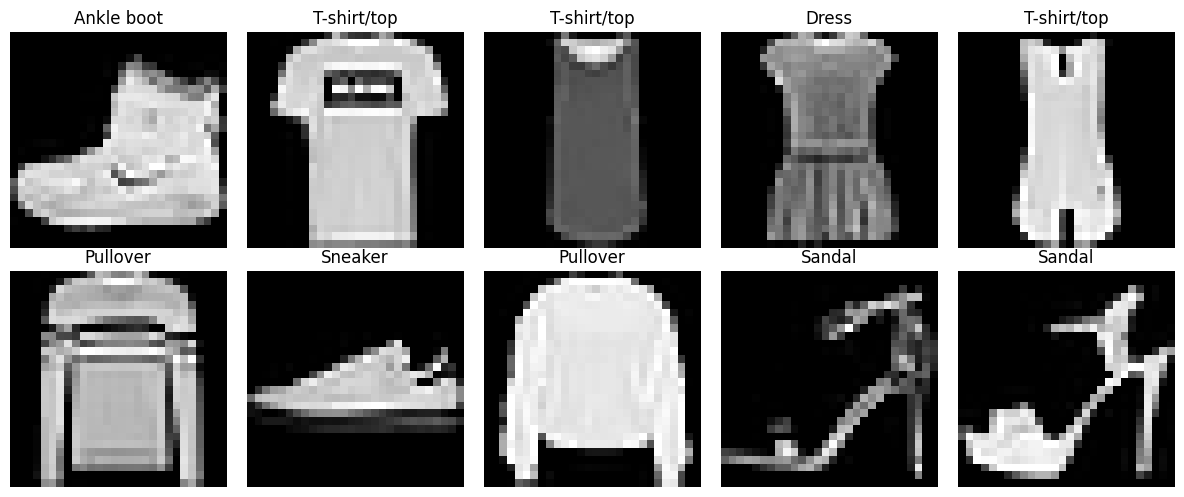

In [7]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_full[i], cmap="gray")
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

T-shirt/top  6000
Trouser      6000
Pullover     6000
Dress        6000
Coat         6000
Sandal       6000
Shirt        6000
Sneaker      6000
Bag          6000
Ankle boot   6000


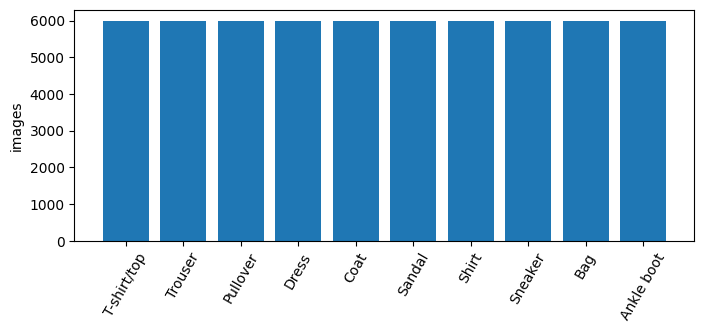

In [8]:
counts = np.bincount(y_train_full)
for name, c in zip(class_names, counts):
    print(f"{name:12s} {c}")

plt.figure(figsize=(8, 3))
plt.bar(class_names, counts)
plt.xticks(rotation=60)
plt.ylabel("images")
plt.show()

**Answer:**
- We normalize (divide by 255) so the pixels are small numbers between 0 and 1 instead of 0–255; this makes training faster and more stable.
- Yes, the dataset is balanced: every class has exactly 6000 training images, so the model is not pushed towards one class.

## Task 2 — Train a Baseline Model
Baseline: `Flatten` → `Dense(32, relu)` → `Dense(10, softmax)`, Adam, 10 epochs, batch size 32.

In [9]:
history = run("Baseline", "Task 2", "none (baseline)")
model = models["Baseline"]
model.summary()

Baseline: epochs=10 | train acc=0.8940 | val acc=0.8795 | val loss=0.3510 | time=37.4s


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,352 (298.25 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 50,902 (198.84 KB)

In [10]:
train_acc = history.history["accuracy"][-1]
val_acc   = history.history["val_accuracy"][-1]
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print("Training accuracy  :", round(train_acc, 4))
print("Validation accuracy:", round(val_acc, 4))
print("Test accuracy      :", round(test_acc, 4))

Training accuracy  : 0.894
Validation accuracy: 0.8795
Test accuracy      : 0.8694


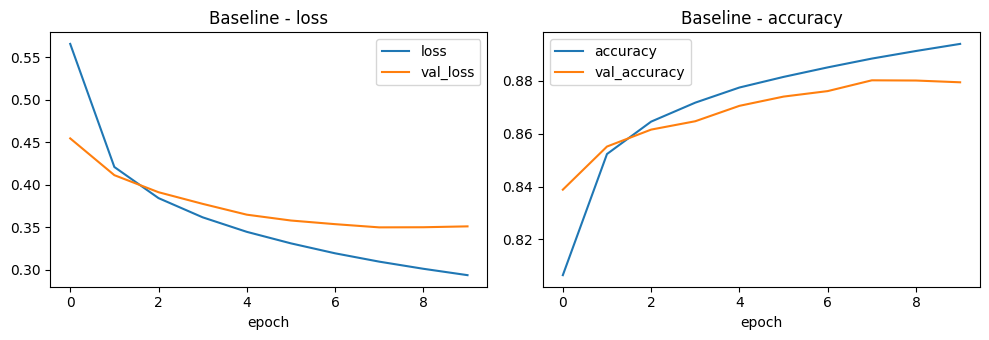

In [11]:
plot_history(history, "Baseline")

**Answer:**
- `Flatten` turns the 28×28 image into one row of 784 numbers so the Dense layer can take it. `ReLU` is the activation of the hidden layer: it keeps positive values and turns negative ones to 0, which lets the network learn more than a straight line. `Softmax` is in the output layer: it turns the 10 outputs into 10 probabilities that add up to 1.
- Results: train accuracy 89.4%, validation accuracy 87.95%, test accuracy 86.94%. Both curves are going in the right direction (loss goes down, accuracy goes up) and train is only a little better than validation, so no big overfitting at 10 epochs.

## Task 3 — Analyze Predictions
I use the baseline model on the test set and pick 1 correct and 2 incorrect predictions.

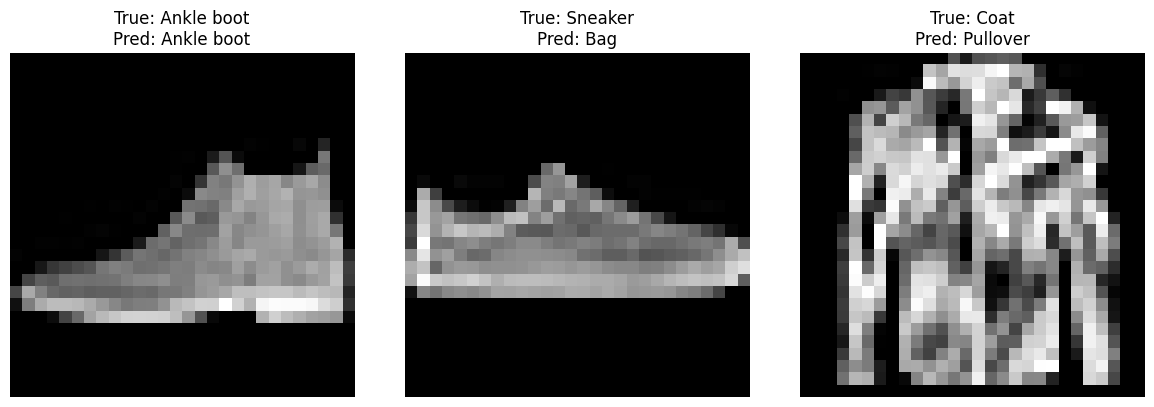

image 0: true = Ankle boot, predicted = Ankle boot, prob of predicted class = 85.77%, prob of true class = 85.77%
image 12: true = Sneaker, predicted = Bag, prob of predicted class = 57.43%, prob of true class = 41.00%
image 17: true = Coat, predicted = Pullover, prob of predicted class = 82.54%, prob of true class = 14.99%


In [12]:
probs = model.predict(x_test, verbose=0)     # shape (10000, 10)
preds = np.argmax(probs, axis=1)

correct_idx = np.where(preds == y_test)[0]
wrong_idx   = np.where(preds != y_test)[0]
chosen = [correct_idx[0], wrong_idx[0], wrong_idx[1]]

plt.figure(figsize=(12, 4))
for k, i in enumerate(chosen):
    plt.subplot(1, 3, k + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"True: {class_names[y_test[i]]}\nPred: {class_names[preds[i]]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

for i in chosen:
    print(f"image {i}: true = {class_names[y_test[i]]}, predicted = {class_names[preds[i]]}, "
          f"prob of predicted class = {probs[i][preds[i]]:.2%}, prob of true class = {probs[i][y_test[i]]:.2%}")

**Answer:**
- The image (28×28) is flattened to 784 values → the hidden layer multiplies them by weights, adds bias and applies ReLU (32 values) → the output layer does the same and Softmax gives 10 probabilities → the biggest probability is the prediction.
- Wrong predictions: a **Coat** was predicted as **Pullover** (82.5% for Pullover, only 15% for the true class) and a **Sneaker** was predicted as **Bag** (57% vs 41%, so the model was not sure). The Coat/Pullover pair may be confusing because both are long-sleeved clothes with a similar shape in a small 28×28 picture, but I can't know the exact reason from the prediction alone.

## Task 4 — Compare Epochs
A fresh model for each run: 5, 10 and 20 epochs. Everything else is the same.

5 epochs: epochs=5 | train acc=0.8775 | val acc=0.8706 | val loss=0.3647 | time=21.7s


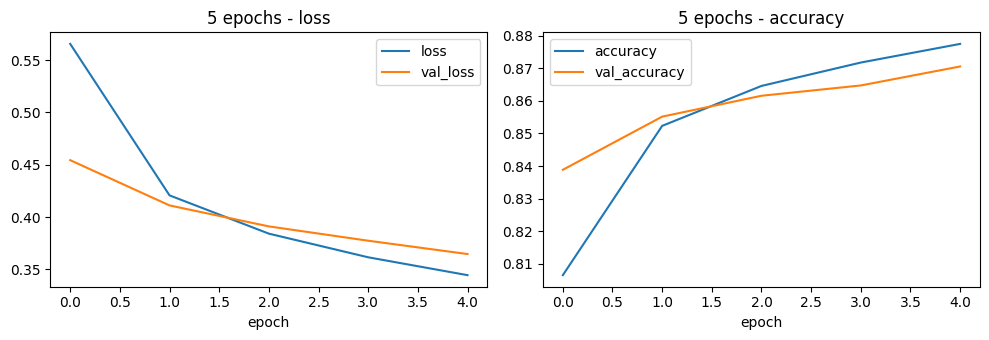

10 epochs: epochs=10 | train acc=0.8940 | val acc=0.8795 | val loss=0.3510 | time=39.8s


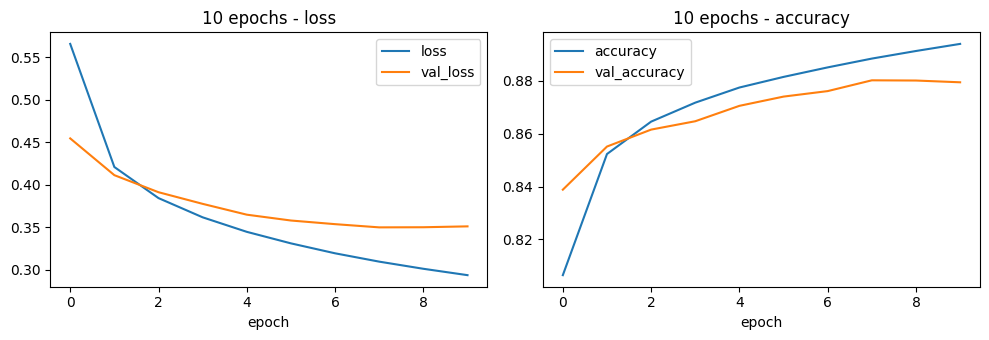

20 epochs: epochs=20 | train acc=0.9112 | val acc=0.8832 | val loss=0.3650 | time=70.9s


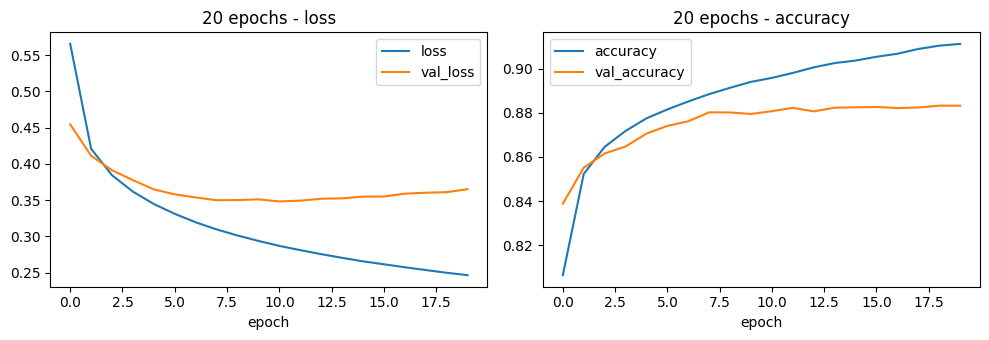

In [13]:
hist_ep = {}
for ep in [5, 10, 20]:
    hist_ep[ep] = run(f"{ep} epochs", "Task 4", f"epochs = {ep}", epochs=ep)
    plot_history(hist_ep[ep], f"{ep} epochs")

In [14]:
for ep in [5, 10, 20]:
    h = hist_ep[ep].history
    best = int(np.argmax(h["val_accuracy"])) + 1
    print(f"{ep:2d} epochs -> best val acc = {max(h['val_accuracy']):.4f} (epoch {best}) | "
          f"last train acc = {h['accuracy'][-1]:.4f} | best val loss = {min(h['val_loss']):.4f} "
          f"(epoch {int(np.argmin(h['val_loss'])) + 1})")

 5 epochs -> best val acc = 0.8706 (epoch 5) | last train acc = 0.8775 | best val loss = 0.3647 (epoch 5)
10 epochs -> best val acc = 0.8802 (epoch 8) | last train acc = 0.8940 | best val loss = 0.3498 (epoch 8)
20 epochs -> best val acc = 0.8832 (epoch 19) | last train acc = 0.9112 | best val loss = 0.3481 (epoch 11)


**Answer:**
- Best validation accuracy: 5 epochs = 87.06%, 10 epochs = 88.02%, 20 epochs = 88.32%.
- The **20-epoch run** shows signs of overfitting: train accuracy keeps going up (91.1%) but the validation loss is best at epoch 11 (0.348) and then gets worse (0.365 at the end).
- So more training is **not always better**: after some point the validation loss stops improving (and the validation accuracy only improves a tiny bit) while training takes longer.

## Task 5 — EarlyStopping Experiment
Max 40 epochs. Run A: no EarlyStopping. Run B: patience=3. Run C: patience=5 (both with `restore_best_weights=True`).

In [15]:
hist_A = run("Run A (no EarlyStopping)", "Task 5", "no EarlyStopping", epochs=40)
hist_B = run("Run B (patience=3)", "Task 5", "EarlyStopping patience=3", epochs=40,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
hist_C = run("Run C (patience=5)", "Task 5", "EarlyStopping patience=5", epochs=40,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])

Run A (no EarlyStopping): epochs=40 | train acc=0.9290 | val acc=0.8774 | val loss=0.4334 | time=118.1s


Run B (patience=3): epochs=14 | train acc=0.9025 | val acc=0.8808 | val loss=0.3481 | time=41.5s


Run C (patience=5): epochs=16 | train acc=0.9054 | val acc=0.8808 | val loss=0.3481 | time=47.8s


Run A: epochs trained = 40 | best val loss = 0.3481 at epoch 11
Run B: epochs trained = 14 | best val loss = 0.3481 at epoch 11
Run C: epochs trained = 16 | best val loss = 0.3481 at epoch 11


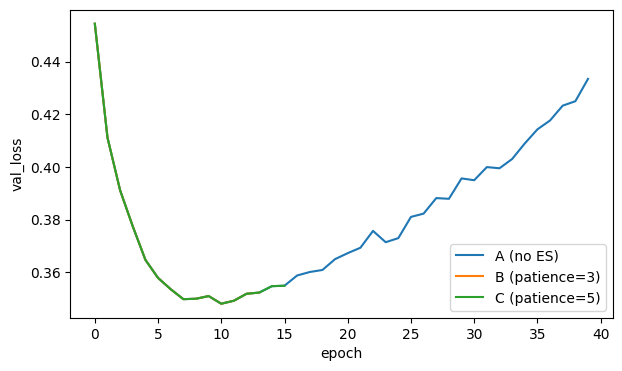

In [16]:
for name, h in [("A", hist_A), ("B", hist_B), ("C", hist_C)]:
    print(f"Run {name}: epochs trained = {len(h.history['loss'])} | best val loss = {min(h.history['val_loss']):.4f} "
          f"at epoch {int(np.argmin(h.history['val_loss'])) + 1}")

plt.figure(figsize=(7, 4))
plt.plot(hist_A.history["val_loss"], label="A (no ES)")
plt.plot(hist_B.history["val_loss"], label="B (patience=3)")
plt.plot(hist_C.history["val_loss"], label="C (patience=5)")
plt.xlabel("epoch"); plt.ylabel("val_loss"); plt.legend(); plt.show()

**Answer:**
- Run A trained all 40 epochs: its best val loss was 0.348 (epoch 11) but at the end it was 0.433 and the final val accuracy was 87.74%. Run B stopped after 14 epochs and Run C after 16 epochs; both went back to the epoch-11 weights, so both got val loss 0.348 and val accuracy 88.08%.
- `patience=3` (or 5) means: wait 3 (or 5) epochs without improvement in `val_loss` and then stop. EarlyStopping helps because it stops before the model overfits, saves time (118s vs ~41–48s) and `restore_best_weights=True` gives back the best model. Here patience 3 and 5 gave the same result, patience 3 was just faster.

## Task 6 — Hidden Neurons Experiment
16, 32 and 128 neurons. Epochs (10), batch size (32), optimizer (Adam) and data split are fixed.

In [17]:
hist_n = {}
for n in [16, 32, 128]:
    hist_n[n] = run(f"{n} neurons", "Task 6", f"hidden neurons = {n}", neurons=n)

16 neurons: epochs=10 | train acc=0.8765 | val acc=0.8653 | val loss=0.3858 | time=31.4s


32 neurons: epochs=10 | train acc=0.8940 | val acc=0.8795 | val loss=0.3510 | time=31.9s


128 neurons: epochs=10 | train acc=0.9135 | val acc=0.8838 | val loss=0.3455 | time=45.5s


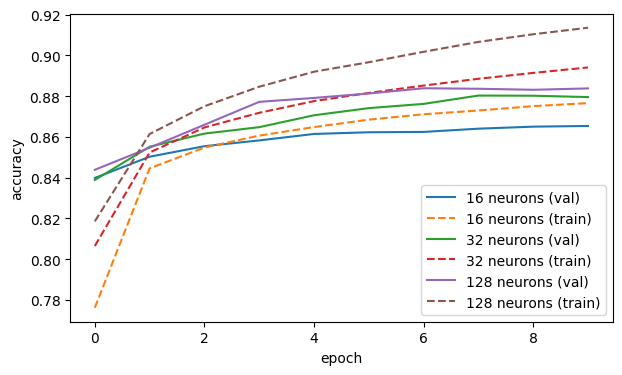

In [18]:
plt.figure(figsize=(7, 4))
for n in [16, 32, 128]:
    plt.plot(hist_n[n].history["val_accuracy"], label=f"{n} neurons (val)")
    plt.plot(hist_n[n].history["accuracy"], "--", label=f"{n} neurons (train)")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.show()

**Answer:**
- Validation accuracy: 16 neurons = 86.53%, 32 neurons = 87.95%, 128 neurons = 88.38%. In this experiment more neurons helped each time, but the gain got smaller (4× more neurons than 32 gave only +0.4%), and it is not guaranteed to always improve.
- Trade-off: the 128-neuron model has higher train accuracy (91.35%) so the gap between train and val is bigger (more risk of overfitting), and it needs more training time (45s vs 32s).

## Task 7 — Batch Size Experiment
Batch size 8, 32 and 128. Architecture, optimizer and epochs are fixed.

In [19]:
hist_b = {}
for b in [8, 32, 128]:
    hist_b[b] = run(f"batch size {b}", "Task 7", f"batch_size = {b}", batch_size=b)

batch size 8: epochs=10 | train acc=0.8960 | val acc=0.8719 | val loss=0.3654 | time=112.2s


batch size 32: epochs=10 | train acc=0.8940 | val acc=0.8795 | val loss=0.3510 | time=27.3s


batch size 128: epochs=10 | train acc=0.8835 | val acc=0.8622 | val loss=0.3763 | time=13.2s


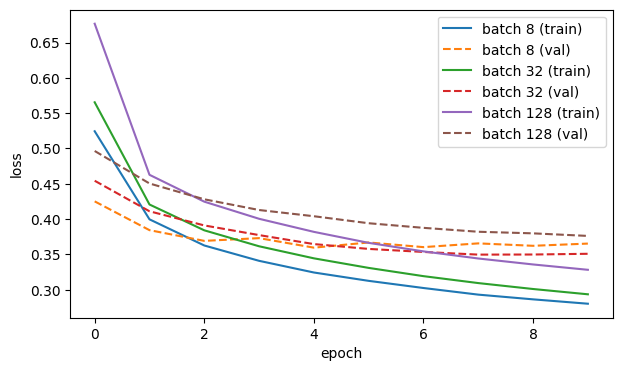

batch   8: weight updates per epoch =  6000 | time per epoch = 11.2s
batch  32: weight updates per epoch =  1500 | time per epoch = 2.7s
batch 128: weight updates per epoch =   375 | time per epoch = 1.3s


In [20]:
plt.figure(figsize=(7, 4))
for b in [8, 32, 128]:
    plt.plot(hist_b[b].history["loss"], label=f"batch {b} (train)")
    plt.plot(hist_b[b].history["val_loss"], "--", label=f"batch {b} (val)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

for b in [8, 32, 128]:
    steps = int(np.ceil(len(x_train) / b))
    row = [r for r in results if r["Experiment"] == f"batch size {b}"][0]
    print(f"batch {b:3d}: weight updates per epoch = {steps:5d} | time per epoch = {row['Time (s)'] / 10:.1f}s")

**Answer:**
- The number of weight updates per epoch = number of images ÷ batch size: batch 8 → 6000 updates, batch 32 → 1500, batch 128 → 375. Smaller batch = more updates = slower epoch (11.2s, 2.7s and 1.3s per epoch).
- Validation accuracy: batch 8 = 87.19%, batch 32 = 87.95%, batch 128 = 86.22%. **Batch size 32** worked best here: more accurate than 128 and about 4× faster than 8.

## Task 8 — Optimizer Comparison
SGD(0.01), SGD(0.01, momentum=0.9), Adam(0.001), plus the optional AdamW.

In [21]:
opts = {
    "SGD lr=0.01":           lambda: keras.optimizers.SGD(learning_rate=0.01),
    "SGD lr=0.01 momentum=0.9": lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "Adam lr=0.001":         lambda: keras.optimizers.Adam(learning_rate=0.001),
    "AdamW (optional)":      lambda: keras.optimizers.AdamW(learning_rate=0.001),
}
hist_o = {}
for name, make in opts.items():
    hist_o[name] = run(name, "Task 8", f"optimizer = {name}", optimizer=make())

SGD lr=0.01: epochs=10 | train acc=0.8590 | val acc=0.8552 | val loss=0.4212 | time=28.4s


SGD lr=0.01 momentum=0.9: epochs=10 | train acc=0.8870 | val acc=0.8733 | val loss=0.3661 | time=26.1s


Adam lr=0.001: epochs=10 | train acc=0.8940 | val acc=0.8795 | val loss=0.3510 | time=31.4s


AdamW (optional): epochs=10 | train acc=0.8933 | val acc=0.8802 | val loss=0.3485 | time=32.3s


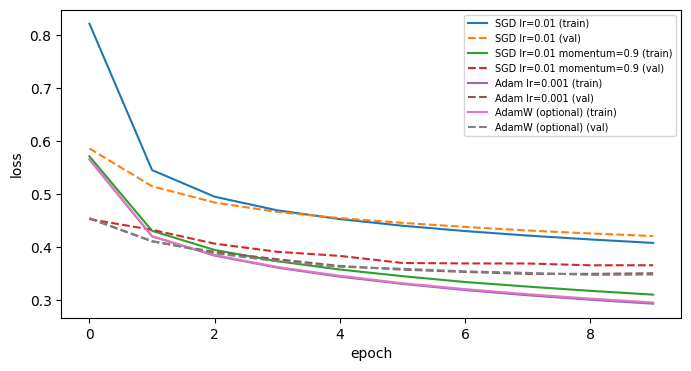

SGD lr=0.01                val acc after epoch 1 = 0.8054 | after epoch 10 = 0.8552
SGD lr=0.01 momentum=0.9   val acc after epoch 1 = 0.8363 | after epoch 10 = 0.8733
Adam lr=0.001              val acc after epoch 1 = 0.8388 | after epoch 10 = 0.8795
AdamW (optional)           val acc after epoch 1 = 0.8379 | after epoch 10 = 0.8802


In [22]:
plt.figure(figsize=(8, 4))
for name in opts:
    plt.plot(hist_o[name].history["loss"], label=name + " (train)")
    plt.plot(hist_o[name].history["val_loss"], "--", label=name + " (val)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(fontsize=7); plt.show()

for name in opts:
    print(f"{name:26s} val acc after epoch 1 = {hist_o[name].history['val_accuracy'][0]:.4f} | after epoch 10 = {hist_o[name].history['val_accuracy'][-1]:.4f}")

**Answer:**
- **Adam** improved fastest (83.88% val accuracy after the first epoch, 87.95% after 10), then SGD with momentum (83.63% → 87.33%). Plain SGD was the slowest (80.54% → 85.52%). AdamW (optional) was almost the same as Adam (88.02%).
- Plain SGD updates the weights using only the current gradient. Momentum also keeps a part of the previous update (like a rolling ball), so it moves faster in the right direction and is less shaky.

## Task 9 — Activation Function Comparison
Hidden activation: `relu` (baseline), `tanh`, `gelu` (optional). Softmax in the output layer stays the same.

hidden relu: epochs=10 | train acc=0.8940 | val acc=0.8795 | val loss=0.3510 | time=32.0s


hidden tanh: epochs=10 | train acc=0.8962 | val acc=0.8687 | val loss=0.3809 | time=32.0s


hidden gelu: epochs=10 | train acc=0.8944 | val acc=0.8762 | val loss=0.3595 | time=31.8s


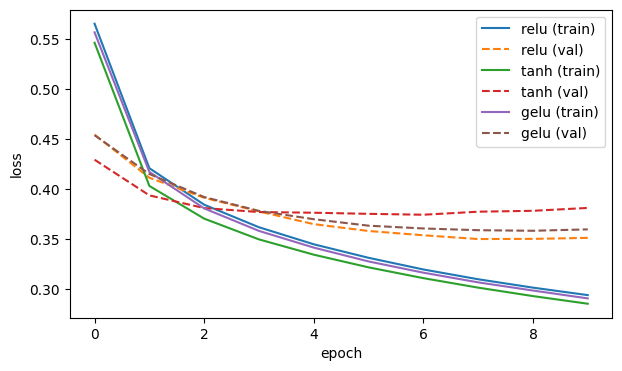

In [23]:
hist_a = {}
for act in ["relu", "tanh", "gelu"]:
    hist_a[act] = run(f"hidden {act}", "Task 9", f"hidden activation = {act}", activation=act)

plt.figure(figsize=(7, 4))
for act in hist_a:
    plt.plot(hist_a[act].history["loss"], label=act + " (train)")
    plt.plot(hist_a[act].history["val_loss"], "--", label=act + " (val)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

**Answer:**
- Validation accuracy: relu = 87.95%, gelu = 87.62%, tanh = 86.87%, so `relu` worked best for this model.
- No, one experiment does not prove it is always better: I used only one small model, one seed and 10 epochs, and the difference between relu and gelu is small. Another dataset or model might give a different winner.

## Task 10 — Evaluate the Final Model
I pick the model with the best **validation** accuracy from all the experiments, and only then use the test set (once).

In [24]:
df = pd.DataFrame(results)
best_row = df.loc[df["Val accuracy"].idxmax()]
print("Best model on validation:", best_row["Experiment"], "| val acc =", round(best_row["Val accuracy"], 4))

final_model = models[best_row["Experiment"]]
test_loss, test_acc = final_model.evaluate(x_test, y_test, verbose=0)    # test set used ONCE
print("Test accuracy:", round(test_acc, 4), "| test loss:", round(test_loss, 4))

Best model on validation: 128 neurons | val acc = 0.8838


Test accuracy: 0.8734 | test loss: 0.3703


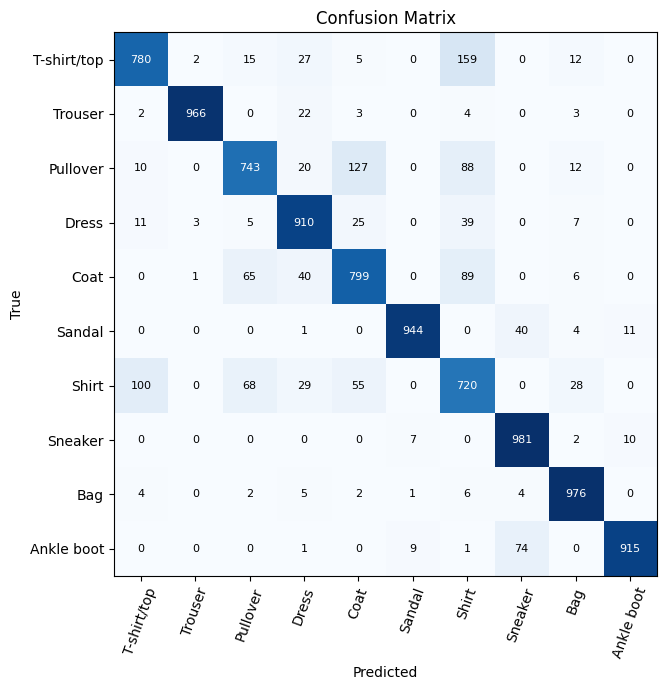

In [25]:
final_preds = np.argmax(final_model.predict(x_test, verbose=0), axis=1)
cm = tf.math.confusion_matrix(y_test, final_preds).numpy()

plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(10), class_names, rotation=70)
plt.yticks(range(10), class_names)
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix")
plt.tight_layout(); plt.show()

In [26]:
# most confused pairs = biggest numbers outside the diagonal
pairs = []
for i in range(10):
    for j in range(10):
        if i != j:
            pairs.append((cm[i, j], class_names[i], class_names[j]))
pairs.sort(reverse=True)
for count, true_c, pred_c in pairs[:4]:
    print(f"{count} times: true {true_c}  ->  predicted {pred_c}")

# accuracy per class
print()
per_class = cm.diagonal() / cm.sum(axis=1)
for name, a in sorted(zip(class_names, per_class), key=lambda x: x[1]):
    print(f"{name:12s} {a:.2%}")

159 times: true T-shirt/top  ->  predicted Shirt
127 times: true Pullover  ->  predicted Coat
100 times: true Shirt  ->  predicted T-shirt/top
89 times: true Coat  ->  predicted Shirt

Shirt        72.00%
Pullover     74.30%
T-shirt/top  78.00%
Coat         79.90%
Dress        91.00%
Ankle boot   91.50%
Sandal       94.40%
Trouser      96.60%
Bag          97.60%
Sneaker      98.10%


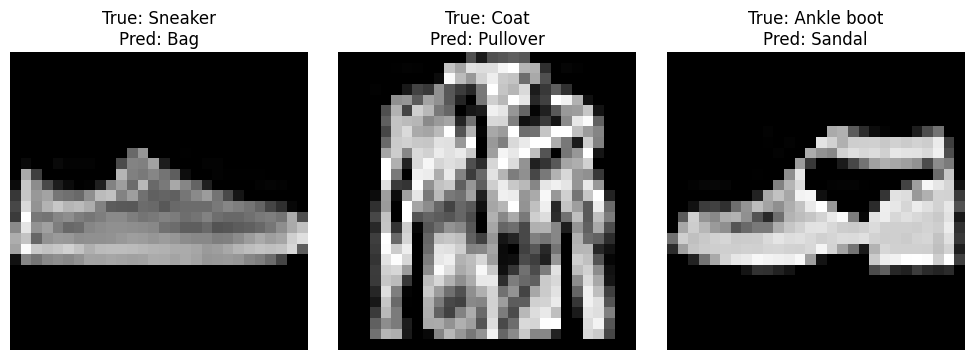

In [27]:
wrong = np.where(final_preds != y_test)[0][:3]
plt.figure(figsize=(10, 3.5))
for k, i in enumerate(wrong):
    plt.subplot(1, 3, k + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"True: {class_names[y_test[i]]}\nPred: {class_names[final_preds[i]]}")
    plt.axis("off")
plt.tight_layout(); plt.show()

**Answer:**
- The best validation model was the one with **128 neurons** (val accuracy 88.38%). I evaluated it once on the test set: **test accuracy = 87.34%**.
- Most confused pairs: T-shirt/top → Shirt (159 times), Pullover → Coat (127 times), Shirt → T-shirt/top (100 times) and Coat → Shirt (89 times). The hardest classes are **Shirt (72%), Pullover (74%), T-shirt/top (78%) and Coat (80%)** — all are tops with a similar shape; the easiest are Sneaker, Bag and Trouser (above 96%).
- Improvement to test next: a **CNN**, because it looks at small parts of the image (sleeves, collar, shape) instead of just flat pixels, so it should separate these similar classes better.

## Comparison table (all experiments)

In [28]:
table = pd.DataFrame(results)[["Task", "Experiment", "Setting changed", "Epochs trained", "Val accuracy"]]
table["Val accuracy"] = table["Val accuracy"].round(4)
table

,Task,Experiment,Setting changed,Epochs trained,Val accuracy
0,Task 2,Baseline,none (baseline),10,0.8795
1,Task 4,5 epochs,epochs = 5,5,0.8706
2,Task 4,10 epochs,epochs = 10,10,0.8795
3,Task 4,20 epochs,epochs = 20,20,0.8832
4,Task 5,Run A (no EarlyStopping),no EarlyStopping,40,0.8774
5,Task 5,Run B (patience=3),EarlyStopping patience=3,14,0.8808
6,Task 5,Run C (patience=5),EarlyStopping patience=5,16,0.8808
7,Task 6,16 neurons,hidden neurons = 16,10,0.8653
8,Task 6,32 neurons,hidden neurons = 32,10,0.8795
9,Task 6,128 neurons,hidden neurons = 128,10,0.8838


**Which configuration did I choose, and why?**

I chose: `Flatten → Dense(128, relu) → Dense(10, softmax)`, Adam, batch size 32, 10 epochs. It had the best validation accuracy (88.38%) and its test accuracy was 87.34%, which is close to the validation result, so the choice is not just luck on the validation set.

What I learned from the experiments:
- More epochs help only until the validation loss stops improving. After that the model overfits, and EarlyStopping saves time and keeps the best weights.
- More neurons helped a little but cost more time and increased the train/validation gap.
- Batch size 32 was a good middle: batch 8 was slow and batch 128 was less accurate.
- Adam learned fastest; momentum makes SGD much better; ReLU was best in this model.
- The differences between many settings are small (less than 1%), and results can change a little between runs, so I should not over-trust a single experiment.
- The biggest problem is not the settings but the model itself: it confuses similar clothes (Shirt, T-shirt, Pullover, Coat), so the next step is a CNN.